# ScamLens-AI: Binary Scam Classification & Triage Benchmark

This notebook evaluates scam detection against real-world sample messages (`data/sample_data.json`) using the **ScamLens-AI Prompt Catalog** (`binary_triage_v1.yaml`) and universal AI client (Groq Llama-3.3, OpenAI, Ollama, etc.).

### Problem Formulation:
The dataset provides flat binary ground truth labels (`0 = Legitimate`, `1 = Scam/Spam`).
To avoid mismatched fine-grained categories (like `PHISHING`, `UPI_FRAUD`, `IMPERSONATION`), the model is prompted to predict strictly:
- **`1`**: Scam / Fraud / Phishing / Deceptive Spam
- **`0`**: Legitimate / Benign Personal / Transactional
- **`None` (`null`)**: Ambiguous / Insufficient context to determine


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import json
import time
from pathlib import Path
from dotenv import load_dotenv
from random import sample

# Ensure project root and src are on sys.path
project_root = Path("..").resolve() if Path("../src").exists() else Path(".").resolve()
src_path = project_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

# Load environment variables from .env
env_file = project_root / ".env"
load_dotenv(env_file) if env_file.exists() else load_dotenv()

from scamlens.ai import get_ai_client, load_prompt, list_available_prompts
from scamlens.core.config import get_settings

settings = get_settings()
client = get_ai_client()

print(f"Project root: {project_root}")
print(f"AI Provider:  {settings.default_ai_provider.upper()}")
print(f"Target Model: {client.model}")
print(f"API Key configured: {bool(client.api_key)}")

Project root: /Users/vishnureddy/PycharmProjects/ScamLens-AI
AI Provider:  CUSTOM
Target Model: Qwen/Qwen3-8B
API Key configured: True


In [3]:
# Load sample dataset
candidates = [
    project_root / "data" / "sample_data.json",
    project_root / "data" / "data.json",
]
data_path = next((p for p in candidates if p.is_file()), None)

if not data_path:
    raise FileNotFoundError(f"Dataset not found in candidates: {candidates}")

with open(data_path, "r", encoding="utf-8") as f:
    data_json = json.load(f)

rows = data_json.get("rows", [])
total_rows = len(rows)
legit_count = sum(1 for r in rows if r.get("label") == 0)
scam_count = sum(1 for r in rows if r.get("label") == 1)

print(f"Successfully loaded {total_rows} records from: {data_path.relative_to(project_root)}")
print(f"Class Distribution: {legit_count} Legitimate (0) | {scam_count} Scam/Spam (1)")

Successfully loaded 3787 records from: data/sample_data.json
Class Distribution: 3040 Legitimate (0) | 747 Scam/Spam (1)


In [4]:
# Load dedicated binary/ternary triage prompt (predicts 1, 0, or null)
available = list_available_prompts()
print(f"Available catalog prompts: {available}")

prompt_name = "binary_triage_v1" if "binary_triage_v1" in available else "text_triage_v1"
prompt = load_prompt(prompt_name)

print(f"\nLoaded prompt template: '{prompt.name}' (v{prompt.version})")
print(f"Description:      {prompt.description}")
print(f"Input variables:  {prompt.input_variables}")
print(f"Model parameters: {prompt.model_parameters}")
print(f"Few-shot pairs:   {len(prompt.few_shot_examples)}")

Available catalog prompts: ['action_guidance_v1', 'binary_triage_v1', 'evidence_synthesis_v1', 'investigation_agent_v1', 'text_triage_v1', 'vision_screenshot_v1']

Loaded prompt template: 'binary_triage_v1' (v1.0.0)
Description:      Ternary/Binary scam triage predicting 1 (scam/spam), 0 (legitimate), or null (uncertain/insufficient), excluding granular sub-classes.
Input variables:  ['text']
Model parameters: {'temperature': 0.0, 'max_tokens': 120, 'response_format': 'json_object'}
Few-shot pairs:   4


In [5]:
# Helper function to parse 1 / 0 / None from model response
def parse_prediction(content: str):
    """Extract prediction (1, 0, or None), confidence, and reason from JSON or text response."""
    try:
        parsed = json.loads(content)
        pred = parsed.get("prediction")
        # Support both 'prediction' (1/0/null) and fallback 'is_suspicious' (bool)
        if pred in (0, 1):
            pred_label = pred
        elif pred is None and "is_suspicious" in parsed:
            is_susp = parsed.get("is_suspicious")
            pred_label = 1 if is_susp is True else (0 if is_susp is False else None)
        else:
            pred_label = None
        confidence = parsed.get("confidence")
        reason = parsed.get("reason") or parsed.get("summary", "")
        return pred_label, confidence, reason
    except Exception:
        upper = content.upper()
        if "SCAM" in upper or "SUSPICIOUS" in upper or "\"PREDICTION\": 1" in upper:
            return 1, None, content[:80]
        elif "LEGITIMATE" in upper or "BENIGN" in upper or "SAFE" in upper or "\"PREDICTION\": 0" in upper:
            return 0, None, content[:80]
        return None, None, content[:80]

# Single test inference on a sample
sample_idx = 150
sample_text = rows[sample_idx]["text"]
sample_label = rows[sample_idx].get("label")  # 0 = legitimate, 1 = scam

# Render OpenAI-compatible messages (system + few-shot examples + target text)
messages = prompt.render_messages(text=sample_text)

response = client.chat_completion(
    messages=messages,
    temperature=prompt.model_parameters.get("temperature", 0.0),
)

content = response["choices"][0]["message"].get("content", "")
pred_label, confidence, reason = parse_prediction(content)

print(f"Sample [{sample_idx}]: {sample_text}")
print(f"True Label:      {sample_label} (0=Legitimate, 1=Scam)")
print(f"Predicted Label: {pred_label} (0=Legit, 1=Scam, None=Uncertain)")
print(f"Confidence:      {confidence}")
print(f"Model Reason:    {reason}")

Sample [150]: Update_Now - Xmas Offer! Latest Motorola, SonyEricsson & Nokia & FREE Bluetooth! Double Mins & 1000 Txt on Orange. Call MobileUpd8 on 08000839402 or call2optout/F4Q=
True Label:      1 (0=Legitimate, 1=Scam)
Predicted Label: 1 (0=Legit, 1=Scam, None=Uncertain)
Confidence:      0.95
Model Reason:    Unsolicited commercial offer with suspicious phone number and potential spam content.


In [6]:
# Batch evaluation loop with rate-limiting throttling
NUM_SAMPLES = 10
DELAY_BETWEEN_CALLS_SEC = 1.5  # Prevents Groq free tier TPM 429 rate limit

indices = sample(range(total_rows), NUM_SAMPLES)
results = []

print(f"Evaluating {len(indices)} samples with model '{client.model}' and prompt '{prompt.name}'...\n")

for count, i in enumerate(indices, start=1):
    row = rows[i]
    query_text = row["text"]
    ground_truth = row.get("label")
    
    messages = prompt.render_messages(text=query_text)
    
    try:
        response = client.chat_completion(
            messages=messages,
            temperature=prompt.model_parameters.get("temperature", 0.0),
        )
        content = response["choices"][0]["message"].get("content", "")
        pred_label, confidence, reason = parse_prediction(content)
    except Exception as exc:
        print(f"[{i:4d}] ⚠️ Error: {exc}")
        continue
        
    if pred_label is None:
        status = "❓ UNCERTAIN"
        is_correct = False
    elif pred_label == ground_truth:
        status = "✅ CORRECT  "
        is_correct = True
    else:
        status = "❌ WRONG    "
        is_correct = False
        
    results.append({
        "index": i,
        "text": query_text,
        "ground_truth": ground_truth,
        "pred_label": pred_label,
        "confidence": confidence,
        "correct": is_correct,
        "reason": reason,
    })
    
    conf_str = f"{confidence:.2f}" if confidence is not None else " N/A"
    preview = (query_text[:50] + "...") if len(query_text) > 50 else query_text
    print(f"[{i:4d}] {status} | Pred: {str(pred_label):4s} (conf: {conf_str}) | True: {ground_truth} | Text: {preview}")
    
    # Throttling to respect token-per-minute (TPM) limits on cloud providers
    if count < len(indices):
        time.sleep(DELAY_BETWEEN_CALLS_SEC)

# Metrics Summary
total_eval = len(results)
correct_count = sum(1 for r in results if r["correct"])
uncertain_count = sum(1 for r in results if r["pred_label"] is None)
decided_count = total_eval - uncertain_count

tp = sum(1 for r in results if r["pred_label"] == 1 and r["ground_truth"] == 1)
fp = sum(1 for r in results if r["pred_label"] == 1 and r["ground_truth"] == 0)
tn = sum(1 for r in results if r["pred_label"] == 0 and r["ground_truth"] == 0)
fn = sum(1 for r in results if r["pred_label"] == 0 and r["ground_truth"] == 1)

accuracy = (correct_count / total_eval) * 100 if total_eval > 0 else 0.0
precision = (tp / (tp + fp)) * 100 if (tp + fp) > 0 else 0.0
recall = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

print("\n" + "=" * 70)
print(f"EVALUATION SUMMARY ({total_eval} samples evaluated)")
print("=" * 70)
print(f"Accuracy:           {correct_count}/{total_eval} ({accuracy:.1f}%)")
print(f"Uncertain/Abstain:  {uncertain_count}/{total_eval} ({(uncertain_count/total_eval)*100:.1f}%)")
print(f"Decided Samples:    {decided_count}")
print(f"Confusion Matrix:   TP={tp}, FP={fp}, TN={tn}, FN={fn}")
print(f"Scam Precision:     {precision:.1f}%")
print(f"Scam Recall:        {recall:.1f}%")
print(f"F1 Score:           {f1:.1f}%")
print("=" * 70)

Evaluating 10 samples with model 'Qwen/Qwen3-8B' and prompt 'binary_triage_v1'...

[3279] ✅ CORRECT   | Pred: 1    (conf: 0.95) | True: 1 | Text: Free Top ringtone -sub to weekly ringtone-get 1st ...
[ 120] ✅ CORRECT   | Pred: 0    (conf: 0.75) | True: 0 | Text: About  &lt;#&gt; bucks. The banks fees are fixed. ...
[  49] ✅ CORRECT   | Pred: 0    (conf: 0.85) | True: 0 | Text: Alright omw, gotta change my order to a half8th
[2163] ✅ CORRECT   | Pred: 0    (conf: 0.75) | True: 0 | Text: I got to video tape pple type in message lor. U so...
[2883] ✅ CORRECT   | Pred: 0    (conf: 0.85) | True: 0 | Text: Yo dude guess who just got arrested the other day
[1001] ✅ CORRECT   | Pred: 1    (conf: 0.95) | True: 1 | Text: URGENT! Your Mobile number has been awarded with a...
[ 501] ✅ CORRECT   | Pred: 0    (conf: 0.95) | True: 0 | Text: Well there's not a lot of things happening in Lind...
[ 197] ✅ CORRECT   | Pred: 0    (conf: 0.85) | True: 0 | Text: Hi:)cts employee how are you?
[ 806] ✅ CORREC

---
## Full Dataset Evaluation: Batch Prompting, Recall & Confusion Matrix

### 1. Is it possible to run API calls on a batch of text lines?
**Yes, absolutely!** Instead of sending 3,787 separate HTTP requests (which would take hours, hit rate limits, and waste tokens repeating system prompts), we can **micro-batch** 10–20 messages into a single prompt.

- **Fewer Requests**: Batch size 15 turns 3,787 individual calls into ~252 calls (a ~93% reduction in HTTP overhead).
- **Token Efficiency**: The system prompt and few-shot formatting are shared across the batch, reducing input token usage by ~80%.
- **Rate-Limit Friendly**: Easily stays under the 30 RPM limit on providers like Groq.

### 2. Is Recall the correct metric?
**Recall on the Scam class is the single most vital safety metric**, but it **must not be used alone**:
- **Why Recall is critical**: A **False Negative (FN)** means a scam slips through undetected; the victim loses money or credentials. Caught scams ($TP$) must dominate missed scams ($FN$).
- **Why Recall alone is dangerous**: A trivial model predicting `1` for all messages achieves 100% Recall, but is useless because it blocks legitimate family texts and OTPs (leading to alert fatigue).
- **The Complete Evaluation Framework**:
  1. **Scam Recall ($\frac{TP}{TP + FN}$)**: Measures coverage of threats (Target: > 95%).
  2. **Scam Precision ($\frac{TP}{TP + FP}$)**: Measures trust in alerts (Target: > 85-90%).
  3. **$F_2$ Score**: The industry-standard metric weighting **Recall twice as heavily as Precision**:
     $$F_2 = \frac{5 \cdot \text{Precision} \cdot \text{Recall}}{4 \cdot \text{Precision} + \text{Recall}}$$
  4. **False Positive Rate ($\text{FPR} = \frac{FP}{FP + TN}$)**: Ensures benign traffic is rarely interrupted (Target: < 1-2%).
  5. **Abstention Rate**: Tracks ambiguous messages routed to `None` for human review.


In [7]:
# Batch Prompting Evaluation Engine with Smart Rate-Limit Handling
import math
import time
import re

def evaluate_batch(client, batch_items, max_retries=6):
    """
    Sends a batch of text messages in a single API call.
    Extracts exact retry delay from Groq/provider 429 headers/errors if rate-limited.
    Returns dict mapping item_id -> {'prediction': 1|0|None, 'confidence': float, 'reason': str}
    """
    lines = []
    for item in batch_items:
        clean_text = item['text'].replace('\n', ' ').strip()
        lines.append(f'[{item["id"]}] "{clean_text}"')
    
    batch_prompt_text = '\n'.join(lines)
    
    messages = [
        {
            'role': 'system',
            'content': (
                'You are an expert fraud and spam detection triage specialist for ScamLens-AI.\n'
                'Classify each numbered message below strictly into one of three verdicts:\n'
                '- 1: Scam, fraud, deceptive spam, phishing, fake prize/loan, or unsolicited commercial lure.\n'
                '- 0: Legitimate, personal, normal transactional notification, or benign conversational message.\n'
                '- null: Ambiguous, incomplete, or insufficient information to determine legitimacy.\n\n'
                'Output strictly valid JSON with this exact schema:\n'
                '{\n'
                '  "results": [\n'
                '    {"id": <int>, "prediction": 1 | 0 | null, "confidence": <float 0.0-1.0>, "reason": "<short explanation>"}\n'
                '  ]\n'
                '}'
            ),
        },
        {
            'role': 'user',
            'content': f'Classify the following {len(batch_items)} messages:\n\n{batch_prompt_text}',
        },
    ]

    for attempt in range(max_retries):
        try:
            response = client.chat_completion(
                messages=messages,
                temperature=0.0,
            )
            content = response['choices'][0]['message'].get('content', '')
            data = json.loads(content)
            results_list = data.get('results', [])
            return {r['id']: r for r in results_list if 'id' in r}
        except Exception as e:
            err_str = str(e)
            if '429' in err_str or 'rate_limit' in err_str.lower():
                # Parse provider suggested delay: e.g. 'Please try again in 4.56s.'
                match = re.search(r'try again in ([0-9.]+)s', err_str, re.IGNORECASE)
                if match:
                    wait_time = float(match.group(1)) + 1.5  # Add 1.5s buffer
                else:
                    wait_time = (attempt + 1) * 4.0
                print(f'  [TPM Rate Limit] Pausing {wait_time:.1f}s before retry {attempt + 1}/{max_retries}...')
                time.sleep(wait_time)
            else:
                print(f'  [API Error] {e}')
                if attempt == max_retries - 1:
                    return {}
                time.sleep(2.0)
    return {}


In [8]:
# Run Dataset Evaluation with Progress & Local Checkpointing
# Note: With Groq's 8,000 TPM limit on experimental models, BATCH_SIZE=5 keeps token requests small (~500 tokens)
BATCH_SIZE = 5                   # 5 items per call avoids hitting the 8,000 TPM ceiling
MAX_EVAL_ITEMS = 150             # Set to None to evaluate all 3,787 items, or e.g. 150 for a fast benchmark
DELAY_BETWEEN_BATCHES_SEC = 3.0  # Pause between batches to pace requests safely
CHECKPOINT_FILE = project_root / 'data' / 'benchmark_eval_cache.json'

eval_slice = rows[:MAX_EVAL_ITEMS] if MAX_EVAL_ITEMS else rows
total_to_eval = len(eval_slice)
total_batches = math.ceil(total_to_eval / BATCH_SIZE)

print(f'Starting Batch Evaluation with Model: {client.model}')
print(f'- Dataset slice:    {total_to_eval} items (out of {len(rows)})')
print(f'- Batch size:       {BATCH_SIZE} items/call (~500 tokens/request)')
print(f'- Total API calls:  {total_batches}')
print(f'- Checkpoint file:  {CHECKPOINT_FILE.name}\n')

# Load existing checkpoint if available (enables resuming)
all_eval_results = []
if CHECKPOINT_FILE.exists():
    try:
        with open(CHECKPOINT_FILE, 'r', encoding='utf-8') as f:
            all_eval_results = json.load(f)
        print(f'Loaded existing checkpoint with {len(all_eval_results)} records.\n')
    except Exception:
        all_eval_results = []

already_done_ids = {r['id'] for r in all_eval_results}

start_time = time.time()
for b_idx in range(total_batches):
    batch_start = b_idx * BATCH_SIZE
    batch_end = min(batch_start + BATCH_SIZE, total_to_eval)
    
    current_items = [
        {'id': i, 'text': eval_slice[i]['text'], 'label': eval_slice[i].get('label')}
        for i in range(batch_start, batch_end)
        if i not in already_done_ids
    ]
    
    if not current_items:
        continue

    predictions = evaluate_batch(client, current_items)
    
    if not predictions:
        print(f'Batch {b_idx + 1} produced no predictions. Skipping to avoid corrupting cache...')
        continue

    for item in current_items:
        item_id = item['id']
        pred_info = predictions.get(item_id, {})
        pred_label = pred_info.get('prediction')
        conf = pred_info.get('confidence')
        reason = pred_info.get('reason', '')
        
        all_eval_results.append({
            'id': item_id,
            'text': item['text'],
            'ground_truth': item['label'],
            'pred_label': pred_label,
            'confidence': conf,
            'reason': reason,
        })
        already_done_ids.add(item_id)
        
    # Save checkpoint to disk after each batch
    with open(CHECKPOINT_FILE, 'w', encoding='utf-8') as f:
        json.dump(all_eval_results, f, indent=2)

    progress = min(batch_end, total_to_eval)
    pct = (progress / total_to_eval) * 100
    print(f'Batch {b_idx + 1:2d}/{total_batches} processed ({progress:4d}/{total_to_eval} messages) - {pct:.1f}%')
    
    if b_idx < total_batches - 1:
        time.sleep(DELAY_BETWEEN_BATCHES_SEC)

elapsed = time.time() - start_time
print(f'\nEvaluation finished in {elapsed:.1f}s ({len(all_eval_results)} total items cached).')


Starting Batch Evaluation with Model: Qwen/Qwen3-8B
- Dataset slice:    150 items (out of 3787)
- Batch size:       5 items/call (~500 tokens/request)
- Total API calls:  30
- Checkpoint file:  benchmark_eval_cache.json

Batch  1/30 processed (   5/150 messages) - 3.3%
Batch  2/30 processed (  10/150 messages) - 6.7%
Batch  3/30 processed (  15/150 messages) - 10.0%
Batch  4/30 processed (  20/150 messages) - 13.3%
Batch  5/30 processed (  25/150 messages) - 16.7%
Batch  6/30 processed (  30/150 messages) - 20.0%
Batch  7/30 processed (  35/150 messages) - 23.3%
Batch  8/30 processed (  40/150 messages) - 26.7%
Batch  9/30 processed (  45/150 messages) - 30.0%
Batch 10/30 processed (  50/150 messages) - 33.3%
Batch 11/30 processed (  55/150 messages) - 36.7%
Batch 12/30 processed (  60/150 messages) - 40.0%
Batch 13/30 processed (  65/150 messages) - 43.3%
Batch 14/30 processed (  70/150 messages) - 46.7%
Batch 15/30 processed (  75/150 messages) - 50.0%
Batch 16/30 processed (  80/150

BENCHMARK EVALUATION RESULTS (150 messages)
Accuracy:                   79.33%
Scam Recall (Sensitivity):  96.43%  <-- [Crucial: caught 27/28 scams]
Scam Precision:             84.38%  <-- [Quality: 27/32 flags true]
F1 Score:                   90.00%
F2 Score (Recall-weighted): 93.75%  <-- [2x weight on Recall]
False Positive Rate (FPR):   5.15%  <-- [Benign falsely flagged]
Specificity (True Neg Rate):94.85%
Uncertain / Abstained:      25 (16.7%)

CONFUSION MATRIX (DECIDED SAMPLES):
┌────────────────────┬──────────────────────┬──────────────────────┐
│ Actual \ Predicted │ Predicted Legit (0)  │ Predicted Scam (1)   │
├────────────────────┼──────────────────────┼──────────────────────┤
│ Actual Legit (0)   │ TN = 92              │ FP = 5                │
│ Actual Scam (1)    │ FN = 1               │ TP = 27               │
└────────────────────┴──────────────────────┴──────────────────────┘
* Note: 25 ambiguous/uncertain messages were abstained from binary matrix.


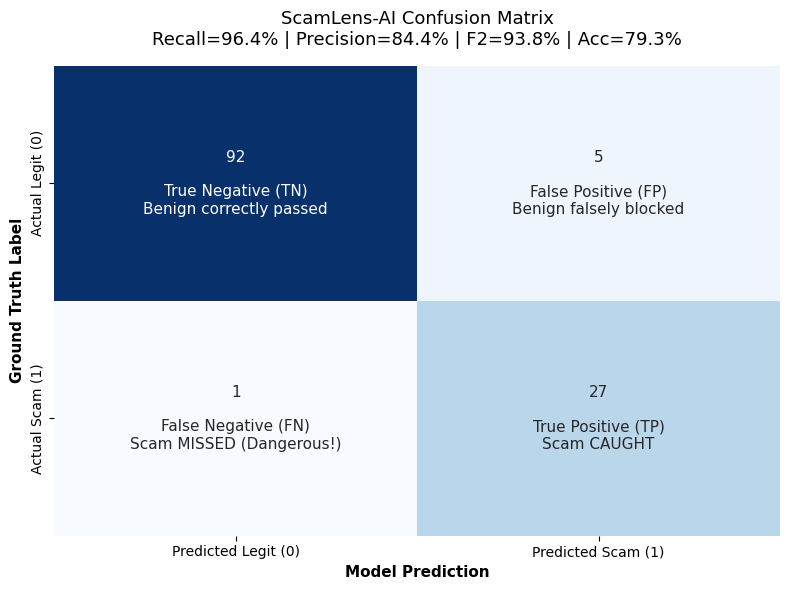

In [9]:
# Metrics Calculation & Confusion Matrix Plotting
try:
    import matplotlib.pyplot as plt
    import seaborn as sns
    HAS_PLOT_LIBS = True
except ImportError:
    HAS_PLOT_LIBS = False

eval_df = [r for r in all_eval_results if r.get('ground_truth') is not None]

# Compute Counts
tp = sum(1 for r in eval_df if r['pred_label'] == 1 and r['ground_truth'] == 1)
fp = sum(1 for r in eval_df if r['pred_label'] == 1 and r['ground_truth'] == 0)
tn = sum(1 for r in eval_df if r['pred_label'] == 0 and r['ground_truth'] == 0)
fn = sum(1 for r in eval_df if r['pred_label'] == 0 and r['ground_truth'] == 1)
uncertain = sum(1 for r in eval_df if r['pred_label'] is None)
total = len(eval_df)
decided = total - uncertain

# Compute Key Metrics
accuracy = (tp + tn) / total * 100 if total > 0 else 0.0
recall = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
precision = (tp / (tp + fp)) * 100 if (tp + fp) > 0 else 0.0
f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
f2 = (5 * precision * recall / (4 * precision + recall)) if (4 * precision + recall) > 0 else 0.0
fpr = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
specificity = (tn / (tn + fp)) * 100 if (tn + fp) > 0 else 0.0

print('=' * 65)
print(f'BENCHMARK EVALUATION RESULTS ({total} messages)')
print('=' * 65)
print(f'Accuracy:                   {accuracy:.2f}%')
print(f'Scam Recall (Sensitivity):  {recall:.2f}%  <-- [Crucial: caught {tp}/{tp+fn} scams]')
print(f'Scam Precision:             {precision:.2f}%  <-- [Quality: {tp}/{tp+fp} flags true]')
print(f'F1 Score:                   {f1:.2f}%')
print(f'F2 Score (Recall-weighted): {f2:.2f}%  <-- [2x weight on Recall]')
print(f'False Positive Rate (FPR):   {fpr:.2f}%  <-- [Benign falsely flagged]')
print(f'Specificity (True Neg Rate):{specificity:.2f}%')
print(f'Uncertain / Abstained:      {uncertain} ({(uncertain/total)*100:.1f}%)')
print('=' * 65)

# Text Confusion Matrix
print('\nCONFUSION MATRIX (DECIDED SAMPLES):')
print('┌────────────────────┬──────────────────────┬──────────────────────┐')
print('│ Actual \\ Predicted │ Predicted Legit (0)  │ Predicted Scam (1)   │')
print('├────────────────────┼──────────────────────┼──────────────────────┤')
print(f'│ Actual Legit (0)   │ TN = {tn:<15d} │ FP = {fp:<16d} │')
print(f'│ Actual Scam (1)    │ FN = {fn:<15d} │ TP = {tp:<16d} │')
print('└────────────────────┴──────────────────────┴──────────────────────┘')
if uncertain > 0:
    print(f'* Note: {uncertain} ambiguous/uncertain messages were abstained from binary matrix.')

# Visual Plot (Seaborn / Matplotlib)
if HAS_PLOT_LIBS:
    cm = [[tn, fp], [fn, tp]]
    labels = [
        ['True Negative (TN)\nBenign correctly passed', 'False Positive (FP)\nBenign falsely blocked'],
        ['False Negative (FN)\nScam MISSED (Dangerous!)', 'True Positive (TP)\nScam CAUGHT'],
    ]
    
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        cm, 
        annot=[[f'{count}\n\n{label}' for count, label in zip(row_c, row_l)] 
               for row_c, row_l in zip(cm, labels)],
        fmt='', 
        cmap='Blues',
        cbar=False,
        xticklabels=['Predicted Legit (0)', 'Predicted Scam (1)'],
        yticklabels=['Actual Legit (0)', 'Actual Scam (1)'],
        annot_kws={'fontsize': 11}
    )
    plt.title(
        f'ScamLens-AI Confusion Matrix\nRecall={recall:.1f}% | Precision={precision:.1f}% | F2={f2:.1f}% | Acc={accuracy:.1f}%', 
        fontsize=13, 
        pad=15
    )
    plt.ylabel('Ground Truth Label', fontsize=11, fontweight='bold')
    plt.xlabel('Model Prediction', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('\nTip: To display the graphical heatmap, install matplotlib and seaborn:')
    print('     %pip install matplotlib seaborn')
